# 01 — Data Cleaning (Mental Health)

Ce notebook reprend **étape par étape** les actions du script `src/preprocessing/cleaning.py` (classe `DataCleaner`), avec pour chaque étape :

- **Action** : ce que fait le code
- **Justification** : pourquoi on le fait, et ce que montrent les résultats

**Ordre du pipeline :** chargement → inspection → nettoyage du texte → conversion des types → valeurs manquantes → outliers → doublons → validation → sauvegarde.

## 0. Imports et chemins

In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


RAW_PATH = "../data/raw/student_mental_health.csv"
CLEAN_PATH = "../data/processed/dataset_clean.csv"

## 1. Chargement du dataset

**Action :** lecture du CSV brut avec `pd.read_csv`.


In [45]:
df = pd.read_csv(RAW_PATH)
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. STRUCTURE DU DATASET

**Action :** Aficher le structure du dataset


In [46]:
print("Dimensions :", df.shape)

print("\nColonnes :")
print(df.columns.tolist())

print("\nTypes et valeurs non nulles :")
df.info()

print("\nStatistiques numériques :")
print(df.describe())

Dimensions : (2000, 17)

Colonnes :
['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']

Types et valeurs non nulles :
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 no

## 3. VALEURS MANQUANTES 
**Action :** afficher les valeurs manquantes


In [47]:
missing = df.isnull().sum()

missing
print(missing[missing > 0].sort_values(ascending=False))

Financial_Stress      91
Diet_Quality          69
Sleep_Hours           62
Social_Media_Hours    58
Family_Support        54
Attendance_Rate       47
GPA                   38
dtype: int64


## 4. DOUBLONS

**Action :** aficher le number DOUBLONS

In [48]:
duplicates = df.duplicated().sum()

print("\n DOUBLONS ")
print("Nombre de doublons :", duplicates)
# 7. Unique values


 DOUBLONS 
Nombre de doublons : 0


## 5. Categorical values

In [49]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False).head(20))


===== Student_ID =====
Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
STU0006    1
STU0007    1
STU0008    1
STU0009    1
STU0010    1
STU0011    1
STU0012    1
STU0013    1
STU0014    1
STU0015    1
STU0016    1
STU0017    1
STU0018    1
STU0019    1
STU0020    1
Name: count, dtype: int64

===== Gender =====
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

===== Physical_Activity =====
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

===== Part_Time_Job =====
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

===== Diet_Quality =====
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

===== Previous_Mental_Health_History =====
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

===== Mental_Health_Risk =====
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dt

/tmp/ipykernel_111894/731942264.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


## Replace with a NAN value

In [50]:
numeric_cols = df.select_dtypes(include="number").columns

print(numeric_cols)

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')


In [51]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(f"\n===== {col} =====")
    print(f"Q1       : {Q1:.2f}")
    print(f"Q3       : {Q3:.2f}")
    print(f"IQR      : {IQR:.2f}")
    print(f"Lower    : {lower:.2f}")
    print(f"Upper    : {upper:.2f}")
    print(f"Outliers : {outliers}")


===== Age =====
Q1       : 20.00
Q3       : 23.00
IQR      : 3.00
Lower    : 15.50
Upper    : 27.50
Outliers : 4

===== Year_of_Study =====
Q1       : 1.00
Q3       : 4.00
IQR      : 3.00
Lower    : -3.50
Upper    : 8.50
Outliers : 0

===== Sleep_Hours =====
Q1       : 6.00
Q3       : 7.60
IQR      : 1.60
Lower    : 3.60
Upper    : 10.00
Outliers : 2

===== Study_Hours_Per_Week =====
Q1       : 16.00
Q3       : 24.00
IQR      : 8.00
Lower    : 4.00
Upper    : 36.00
Outliers : 7

===== GPA =====
Q1       : 2.32
Q3       : 2.79
IQR      : 0.47
Lower    : 1.61
Upper    : 3.50
Outliers : 9

===== Social_Media_Hours =====
Q1       : 5.22
Q3       : 6.70
IQR      : 1.48
Lower    : 3.01
Upper    : 8.91
Outliers : 20

===== Screen_Time_Hours =====
Q1       : 7.40
Q3       : 9.70
IQR      : 2.30
Lower    : 3.95
Upper    : 13.15
Outliers : 7

===== Financial_Stress =====
Q1       : 4.50
Q3       : 7.40
IQR      : 2.90
Lower    : 0.15
Upper    : 11.75
Outliers : 0

===== Family_Support =====
Q1 

## Target Variable Analysis

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


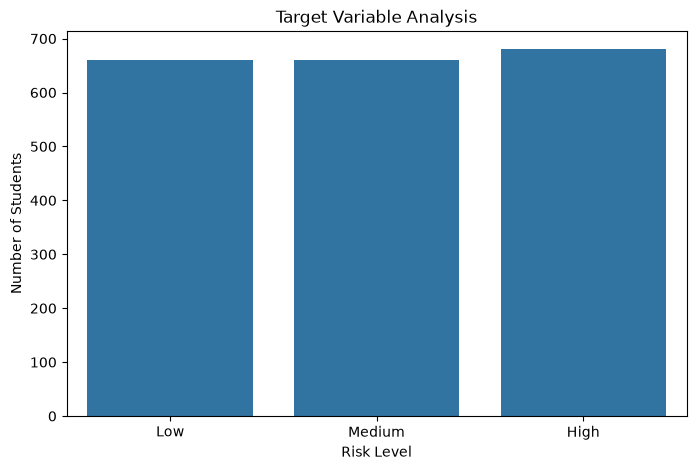

In [52]:
# Target distribution
print(df["Mental_Health_Risk"].value_counts())

# Percentage distribution
print(
    df["Mental_Health_Risk"]
    .value_counts(normalize=True) * 100
)


## target analysis
plt.figure(figsize= (8,5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=["Low", "Medium", "High"]
)
plt.title("Target Variable Analysis")
plt.xlabel("Risk Level")
plt.ylabel("Number of Students")
plt.show()

## Correlation matrix

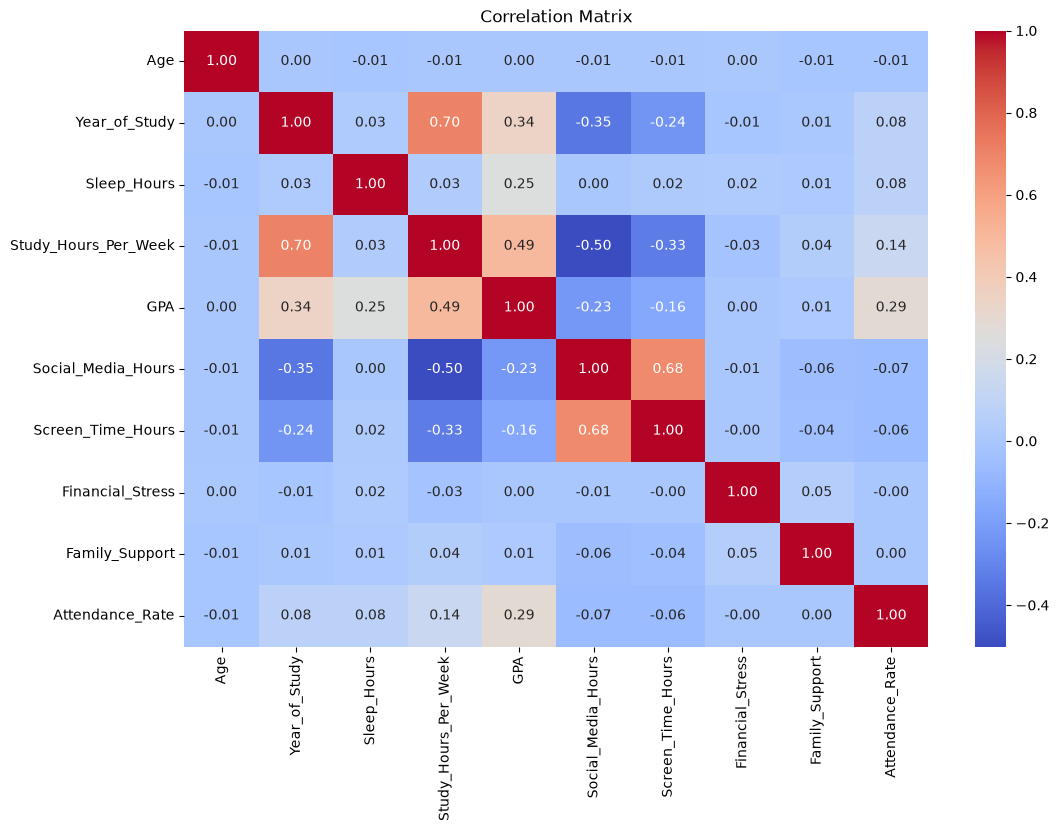

In [53]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()